In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import surprise
from surprise import accuracy


In [2]:
dataset_path = Path('../dataset')
train_df = pd.read_csv(dataset_path / 'train.csv')
train_df.date = pd.to_datetime(train_df.date)

test_df = pd.read_csv(dataset_path / 'validation.csv')
test_df.date = pd.to_datetime(test_df.date)

train_df.head()

,user_id,recipe_id,date,rating
0,1293707,150898,2011-01-04,5
1,1293707,25360,2011-01-04,5
2,1293707,99564,2011-01-06,4
3,1293707,70758,2011-01-09,5
4,1293707,115110,2011-01-26,5


In [3]:
train_df.describe()

,user_id,recipe_id,date,rating
count,1.571080e+05,157108.000000,157108,157108.000000
mean,7.089527e+06,90281.169145,2007-07-23 01:53:33.758688,4.660094
min,1.533000e+03,62.000000,2001-04-18 00:00:00,0.000000
25%,9.757900e+04,32614.000000,2006-01-10 00:00:00,5.000000
50%,2.159560e+05,69484.000000,2007-09-01 00:00:00,5.000000
75%,4.379730e+05,119544.000000,2008-12-31 00:00:00,5.000000
max,2.001453e+09,496591.000000,2018-05-14 00:00:00,5.000000
std,1.130750e+08,76689.736519,NaN,0.833243


In [6]:
test_df

,user_id,recipe_id,date,rating
0,1293707,178556,2011-11-06,5
1,1293707,50144,2011-11-11,5
2,126440,107142,2013-05-15,4
3,126440,38339,2013-05-17,5
4,126440,71557,2013-05-18,5
...,...,...,...,...
27411,1079336,21138,2009-01-10,5
27412,1079336,39087,2009-01-10,5
27413,1079336,221217,2009-01-10,5
27414,18347,58516,2008-10-08,5


In [7]:
reader = surprise.reader.Reader(rating_scale=(0,5))

train_data = surprise.Dataset.load_from_df(
    train_df[["user_id", "recipe_id", "rating"]], reader=reader
)
trainset = train_data.build_full_trainset()

test_data = surprise.Dataset.load_from_df(
    test_df[["user_id", "recipe_id", "rating"]], reader=reader
)
testset = test_data.construct_testset(
    test_data.raw_ratings
)


In [ ]:
k_values = [5, 10, 30, 50, 70, 100]
mae_values = []
rmse_values = []

for k in k_values:
  myUserKnn = surprise.KNNBasic(k=k, sim_options={'name': 'pearson', 'user_based': True})
  myUserKnn.fit(trainset)
  predictions = myUserKnn.test(testset)
  rmse_values.append(accuracy.rmse(predictions))
  mae_values.append(accuracy.mae(predictions))

Text(0.5, 1.0, 'MAE for diferent k values')

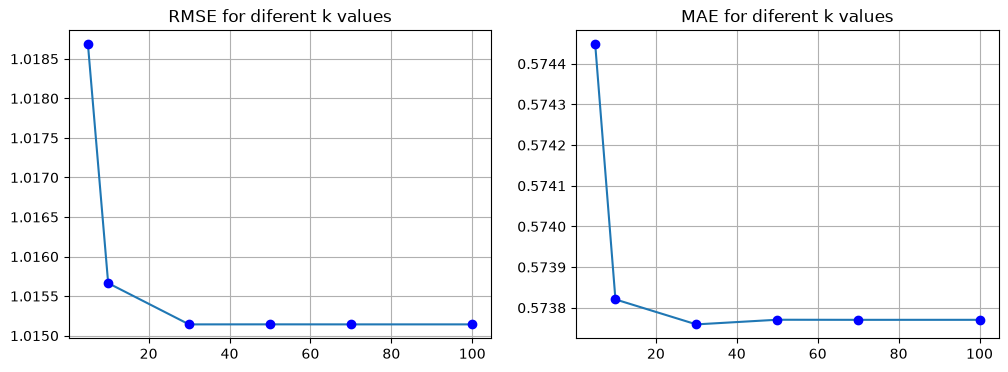

In [ ]:

fig, (rmse_ax, mae_ax)  = plt.subplots(ncols=2, figsize=(12,4))

rmse_ax.plot(k_values, rmse_values)
rmse_ax.plot(k_values, rmse_values, 'bo')
rmse_ax.grid(True)
rmse_ax.set_title('RMSE for diferent k values')

mae_ax.plot(k_values, mae_values)
mae_ax.plot(k_values, mae_values, 'bo')
mae_ax.grid(True)
mae_ax.set_title('MAE for diferent k values')


## Best k for user knn = 30